In [1]:
from pathlib import Path
import pandas as pd

data_dir = Path("../data")

files = sorted(data_dir.glob("entries*of500.csv"))

df = pd.concat(
    [pd.read_csv(file) for file in files],
    ignore_index=True
)

print(f"Loaded {len(files)} batches")
print(f"Total rows: {len(df):,}")
print(f"Unique athletes: {df['ID'].nunique():,}")

Loaded 10 batches
Total rows: 4,749
Unique athletes: 2,711


In [2]:
# data completeness
# investigate how successful scraping has been
athletes = df.drop_duplicates(subset="ID").copy()

columns = [
    "qid",
    "birthdate",
    "deathdate",
    "status",
    "mannerofdeath"
]

athletes[columns].notna().mean().mul(100).round(1)

qid              87.6
birthdate        82.7
deathdate        17.2
status           75.1
mannerofdeath     1.3
dtype: float64

In [4]:
# analyze error messages
errors = (
    athletes["errormessage"]
    .dropna()
    .str.split(" | ", regex=False)
    .explode()
)
errors = errors.str.strip()
errors = errors[errors != ""]

errors.value_counts().head(20)

errormessage
No reliable name match found                               1415
No Wikidata search results found for any name variation     332
At least 2 Wikidata search results found                    117
At least 3 Wikidata search results found                     61
month of birth is missing                                    60
At least 4 Wikidata search results found                     42
month of death is missing                                    41
At least 50 Wikidata search results found                    37
At least 5 Wikidata search results found                     17
At least 6 Wikidata search results found                     16
At least 7 Wikidata search results found                     16
At least 9 Wikidata search results found                     10
At least 15 Wikidata search results found                     7
At least 11 Wikidata search results found                     7
At least 8 Wikidata search results found                      7
At least 14 Wikidata search

In [12]:
# categorize errors
def categorize_error(message):
    if message.startswith("At least ") and "Wikidata search results found" in message:
        return "Multiple Wikidata matches"

    if message.startswith("No Wikidata search results found"):
        return "No Wikidata results"

    if "No reliable name match found" in message:
        return "No reliable Olympedia match"

    if "month of " in message or "day of " in message:
        return "Incomplete date"

    if "Technical error" in message or "Connection error" in message:
        return "Technical error"

    if "failed" in message.lower() or "too busy" in message.lower():
        return "Request failure"
    if "Multiple name matches found" in message:
        return "Multiple Olympedia matches"

    return "Other: " + message

In [13]:
error_categories = errors.map(categorize_error)

error_categories.value_counts()

errormessage
No reliable Olympedia match    1415
Multiple Wikidata matches       419
No Wikidata results             332
Incomplete date                 101
Technical error                   3
Request failure                   2
Multiple Olympedia matches        1
Name: count, dtype: int64

In [14]:
athlete_errors = athletes[["ID", "errormessage"]].copy()

athlete_errors["error"] = athlete_errors["errormessage"].fillna("").str.split(" | ", regex=False)

athlete_errors = athlete_errors.explode("error")

athlete_errors["error"] = athlete_errors["error"].str.strip()
athlete_errors = athlete_errors[athlete_errors["error"] != ""]

athlete_errors["category"] = athlete_errors["error"].map(categorize_error)

In [15]:
error_summary = (
    athlete_errors.groupby("category")["ID"]
    .nunique()
    .sort_values(ascending=False)
    .to_frame("athletes")
)

error_summary["percentage"] = (
    100 * error_summary["athletes"] / athletes["ID"].nunique()
).round(1)

error_summary

,athletes,percentage
category,,
No reliable Olympedia match,1415,52.2
Multiple Wikidata matches,419,15.5
No Wikidata results,332,12.2
Incomplete date,96,3.5
Technical error,3,0.1
Request failure,2,0.1
Multiple Olympedia matches,1,0.0


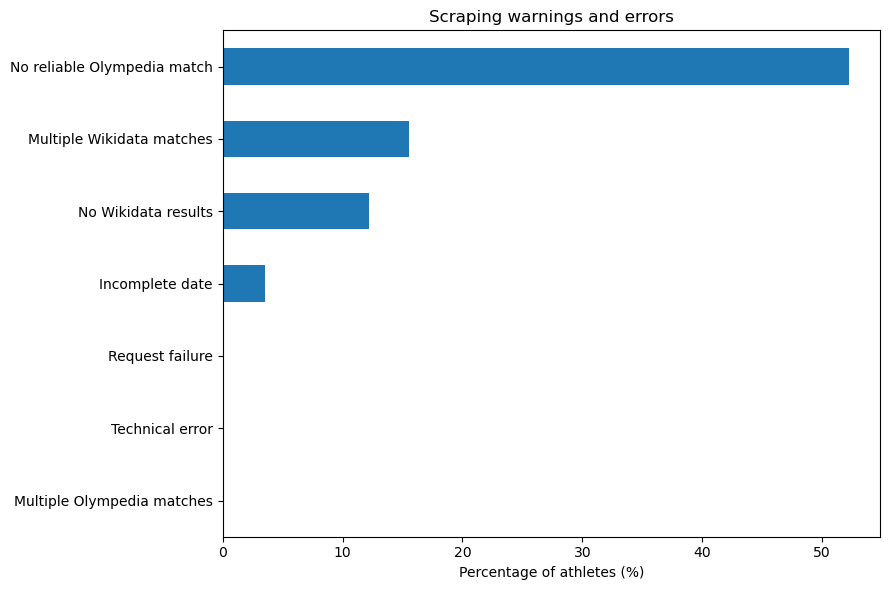

In [16]:
import matplotlib.pyplot as plt

error_summary["percentage"].sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.xlabel("Percentage of athletes (%)")
plt.ylabel("")
plt.title("Scraping warnings and errors")
plt.tight_layout()
plt.show()

# Investigate suspicious matches

In [17]:
df[["ID", "Name", "Year", "birthdate", "deathdate", "qid"]].dtypes

ID            int64
Name         object
Year          int64
birthdate    object
deathdate    object
qid          object
dtype: object

In [18]:
df[["ID", "Name", "Year", "birthdate", "deathdate", "qid"]].head(10)

,ID,Name,Year,birthdate,deathdate,qid
0,2441,Jacky Alders,1976,1956-01-28,NaN,Q6118077
1,2441,Jacky Alders,1980,1956-01-28,NaN,Q6118077
2,2442,Olympia Aldersey,2016,1992-07-26,NaN,Q16002428
3,2443,"Joan ""Jody"" Alderson (-Braskamp)",1952,1935-03-05,2021-02-14,Q2947879
4,2443,"Joan ""Jody"" Alderson (-Braskamp)",1952,1935-03-05,2021-02-14,Q2947879
5,2444,Manole Aldescu,1952,1929-02-18,NaN,Q16091104
6,2444,Manole Aldescu,1956,1929-02-18,NaN,Q16091104
7,2444,Manole Aldescu,1956,1929-02-18,NaN,Q16091104
8,2445,"Robert Mathew ""Bob"" Aldighieri",1992,1965-03-20,NaN,Q97104757
9,2446,Horace James Murrall Aldous,1908,NaN,NaN,NaN


In [21]:
# convert the dates
quality_df = df.copy()

quality_df["birth_year"] = pd.to_numeric(
    quality_df["birthdate"].str.extract(r"^(\d{4})")[0],
    errors="coerce"
)

quality_df["death_year"] = pd.to_numeric(
    quality_df["deathdate"].str.extract(r"^(\d{4})")[0],
    errors="coerce"
)

In [22]:
# calculate age at olympics
quality_df["age_at_olympics"] = (
    quality_df["Year"] - quality_df["birth_year"]
)

In [23]:
# flag suspicious records
quality_df["born_after_olympics"] = (
    quality_df["birth_year"] > quality_df["Year"]
)

quality_df["died_before_olympics"] = (
    quality_df["death_year"] < quality_df["Year"]
)

quality_df["unusual_age"] = (
    (quality_df["age_at_olympics"] < 10)
    | (quality_df["age_at_olympics"] > 80)
)

quality_df["suspicious"] = (
    quality_df["born_after_olympics"]
    | quality_df["died_before_olympics"]
    | quality_df["unusual_age"]
)

In [24]:
# examine the suspicious athletes
suspicious = quality_df[quality_df["suspicious"]]

columns = [
    "ID", "Name", "Year", "qid",
    "birthdate", "deathdate",
    "age_at_olympics",
    "born_after_olympics",
    "died_before_olympics",
    "unusual_age"
]

suspicious[columns].sort_values("ID")

,ID,Name,Year,qid,birthdate,deathdate,age_at_olympics,born_after_olympics,died_before_olympics,unusual_age
589,39,Lars Thorlaksn Aas,1912,Q17094280,1975-01-01,NaN,-63.0,True,False,True
587,39,Lars Thorlaksn Aas,1912,Q17094280,1975-01-01,NaN,-63.0,True,False,True
588,39,Lars Thorlaksn Aas,1912,Q17094280,1975-01-01,NaN,-63.0,True,False,True
635,59,Ivan Nikolov Abadzhiev,1960,Q110752098,1865-09-05,NaN,95.0,False,False,True
634,59,Ivan Nikolov Abadzhiev,1956,Q110752098,1865-09-05,NaN,91.0,False,False,True
...,...,...,...,...,...,...,...,...,...,...
414,2665,Ahmed Khalaf Khalaf Ali,1948,Q100719164,1997-04-10,NaN,-49.0,True,False,True
415,2665,Ahmed Khalaf Khalaf Ali,1948,Q100719164,1997-04-10,NaN,-49.0,True,False,True
435,2679,Haider Ali,2000,Q1569078,1717-01-01,1782-12-07,283.0,False,True,True
450,2688,Mehboob Ali,2016,Q17279131,1931-01-01,2011-01-01,85.0,False,True,True


In [25]:
print(f"Suspicious rows: {len(suspicious):,}")
print(f"Suspicious athletes: {suspicious['ID'].nunique():,}")
print(
    f"Percentage of athletes: "
    f"{100 * suspicious['ID'].nunique() / df['ID'].nunique():.1f}%"
)

Suspicious rows: 202
Suspicious athletes: 106
Percentage of athletes: 3.9%


In [26]:
checks = [
    "born_after_olympics",
    "died_before_olympics",
    "unusual_age"
]

quality_df.groupby("ID")[checks].any().sum()

born_after_olympics      44
died_before_olympics     40
unusual_age             100
dtype: int64

In [27]:
quality_df["too_young"] = quality_df["age_at_olympics"] < 10
quality_df["too_old"] = quality_df["age_at_olympics"] > 80

quality_df.groupby("ID")[["too_young", "too_old"]].any().sum()

too_young    62
too_old      38
dtype: int64

In [28]:
quality_df.loc[
    quality_df["unusual_age"],
    ["ID", "Name", "Year", "qid", "age_at_olympics"]
].sort_values("age_at_olympics")

,ID,Name,Year,qid,age_at_olympics
1355,505,"Alexander ""Alex"" Abraham (Steglitz)",1912,Q2641659,-69.0
1207,416,Nils Georg berg,1912,Q19976356,-65.0
1208,416,Nils Georg berg,1912,Q19976356,-65.0
589,39,Lars Thorlaksn Aas,1912,Q17094280,-63.0
588,39,Lars Thorlaksn Aas,1912,Q17094280,-63.0
...,...,...,...,...,...
1414,528,Karl Gran Abrahamsson,1964,Q141581108,334.0
1413,528,Karl Gran Abrahamsson,1964,Q141581108,334.0
748,139,"George ""Ioannis"" Abbot",1906,Q714925,344.0
2004,844,"William Edward ""Willie"" Adams",1992,Q313866,428.0


In [29]:
# Are athletes with multiple Wikidata search results more likely to have suspicious dates?
athlete_quality = (
    quality_df.groupby("ID")["suspicious"]
    .any()
    .reset_index()
)

athlete_quality = athlete_quality.merge(
    athletes[["ID", "number_of_matches", "qid"]],
    on="ID",
    how="left"
)

In [30]:
athlete_quality["match_group"] = "No Wikidata match"

athlete_quality.loc[
    athlete_quality["number_of_matches"] == 1,
    "match_group"
] = "One Wikidata result"

athlete_quality.loc[
    athlete_quality["number_of_matches"] > 1,
    "match_group"
] = "Multiple Wikidata results"

match_quality = (
    athlete_quality.groupby("match_group")
    .agg(
        athletes=("ID", "count"),
        suspicious=("suspicious", "sum"),
        suspicious_percentage=("suspicious", "mean")
    )
)

match_quality["suspicious_percentage"] *= 100
match_quality.round(1)

,athletes,suspicious,suspicious_percentage
match_group,,,
Multiple Wikidata results,419,92,22.0
No Wikidata match,335,0,0.0
One Wikidata result,1957,14,0.7


In [31]:
athlete_quality["match_count_group"] = pd.cut(
    athlete_quality["number_of_matches"],
    bins=[0, 1, 2, 5, 10, 20, 50],
    labels=["1", "2", "3–5", "6–10", "11–20", "21–50"]
)

match_count_quality = (
    athlete_quality.dropna(subset=["match_count_group"])
    .groupby("match_count_group", observed=True)
    .agg(
        athletes=("ID", "count"),
        suspicious=("suspicious", "sum"),
        suspicious_percentage=("suspicious", "mean")
    )
)

match_count_quality["suspicious_percentage"] *= 100

match_count_quality.round(1)

,athletes,suspicious,suspicious_percentage
match_count_group,,,
1,1957,14,0.7
2,117,15,12.8
3–5,120,26,21.7
6–10,55,15,27.3
11–20,43,7,16.3
21–50,84,29,34.5


In [32]:
# compare athletes with and without reliable Olympedia matches
athlete_quality["olympedia_match"] = ~athletes.set_index("ID").loc[
    athlete_quality["ID"], "errormessage"
].fillna("").str.contains("No reliable name match found").to_numpy()

olympedia_quality = (
    athlete_quality.groupby("olympedia_match")
    .agg(
        athletes=("ID", "count"),
        suspicious=("suspicious", "sum"),
        suspicious_percentage=("suspicious", "mean")
    )
)

olympedia_quality["suspicious_percentage"] *= 100

olympedia_quality.round(1)

,athletes,suspicious,suspicious_percentage
olympedia_match,,,
False,1415,58,4.1
True,1296,48,3.7


In [33]:
lifespan_quality = (
    quality_df.drop_duplicates("ID")
    [["ID", "qid", "birthdate", "deathdate", "status"]]
    .copy()
)

lifespan_quality["has_birthdate"] = lifespan_quality["birthdate"].notna()
lifespan_quality["has_deathdate"] = lifespan_quality["deathdate"].notna()

lifespan_quality["has_lifespan"] = (
    lifespan_quality["has_birthdate"]
    & lifespan_quality["has_deathdate"]
)

lifespan_summary = pd.DataFrame({
    "Athletes": [
        len(lifespan_quality),
        lifespan_quality["qid"].notna().sum(),
        lifespan_quality["has_birthdate"].sum(),
        lifespan_quality["has_deathdate"].sum(),
        lifespan_quality["has_lifespan"].sum()
    ]
}, index=[
    "Total athletes",
    "Wikidata match",
    "Birthdate available",
    "Deathdate available",
    "Complete lifespan available"
])

lifespan_summary["Percentage"] = (
    100 * lifespan_summary["Athletes"] / len(lifespan_quality)
).round(1)

lifespan_summary

,Athletes,Percentage
Total athletes,2711,100.0
Wikidata match,2376,87.6
Birthdate available,2243,82.7
Deathdate available,465,17.2
Complete lifespan available,463,17.1


# Data quality visualizations

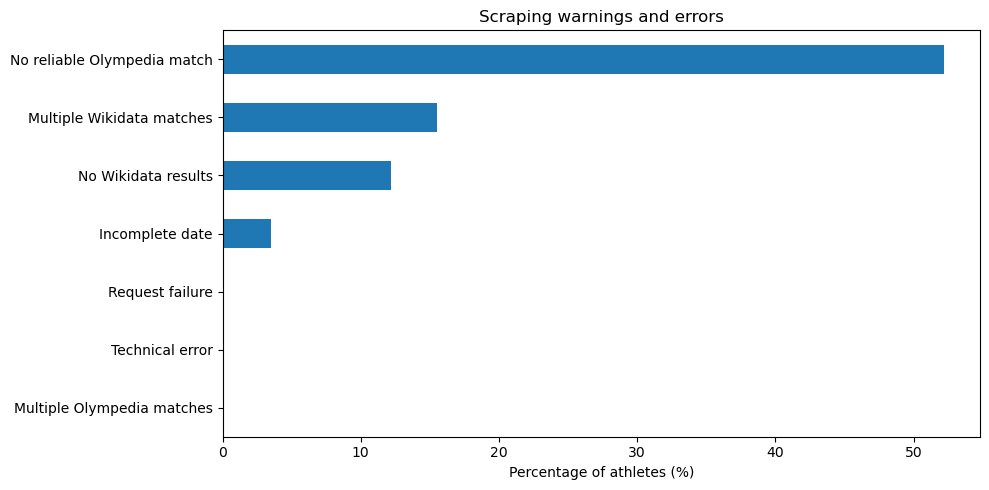

In [34]:
import matplotlib.pyplot as plt

ax = error_summary["percentage"].sort_values().plot(
    kind="barh",
    figsize=(10, 5)
)

ax.set_title("Scraping warnings and errors")
ax.set_xlabel("Percentage of athletes (%)")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

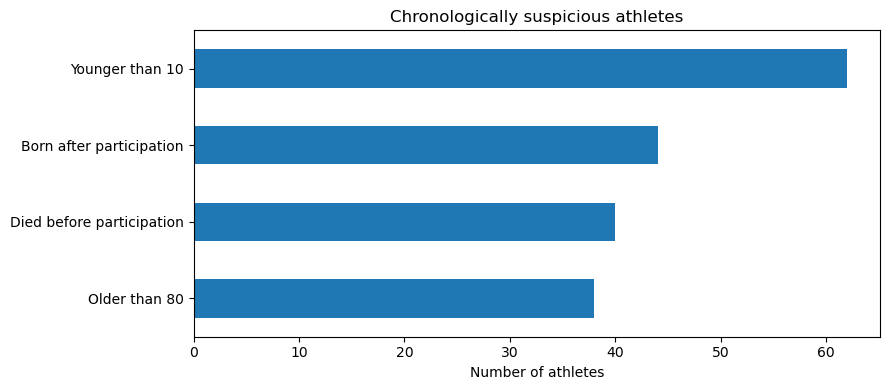

In [35]:
checks = [
    "born_after_olympics",
    "died_before_olympics",
    "too_young",
    "too_old"
]

check_labels = {
    "born_after_olympics": "Born after participation",
    "died_before_olympics": "Died before participation",
    "too_young": "Younger than 10",
    "too_old": "Older than 80"
}

check_counts = (
    quality_df.groupby("ID")[checks]
    .any()
    .sum()
    .rename(index=check_labels)
)

ax = check_counts.sort_values().plot(
    kind="barh",
    figsize=(9, 4)
)

ax.set_title("Chronologically suspicious athletes")
ax.set_xlabel("Number of athletes")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

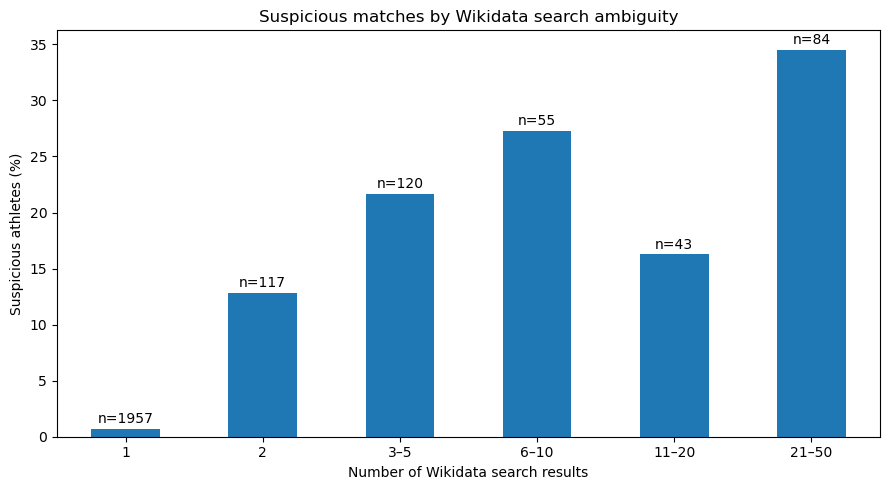

In [37]:
ax = match_count_quality["suspicious_percentage"].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Suspicious matches by Wikidata search ambiguity")
ax.set_xlabel("Number of Wikidata search results")
ax.set_ylabel("Suspicious athletes (%)")

plt.tight_layout()
for i, (_, row) in enumerate(match_count_quality.iterrows()):
    ax.text(
        i,
        row["suspicious_percentage"] + 0.5,
        f"n={int(row['athletes'])}",
        ha="center"
    )
plt.show()

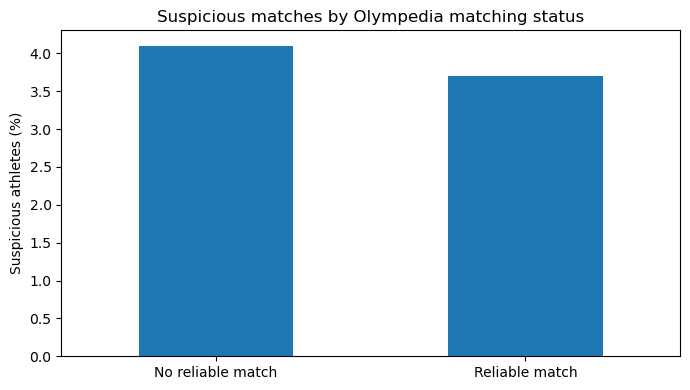

In [38]:
plot_data = olympedia_quality.copy()

plot_data.index = plot_data.index.map({
    False: "No reliable match",
    True: "Reliable match"
})

ax = plot_data["suspicious_percentage"].plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

ax.set_title("Suspicious matches by Olympedia matching status")
ax.set_xlabel("")
ax.set_ylabel("Suspicious athletes (%)")

plt.tight_layout()
plt.show()

# Examine lifespan completeness

In [40]:
lifespan_quality = (
    quality_df.drop_duplicates("ID")
    [["ID", "qid", "birthdate", "deathdate", "status"]]
    .copy()
)

lifespan_quality["has_birthdate"] = lifespan_quality["birthdate"].notna()
lifespan_quality["has_deathdate"] = lifespan_quality["deathdate"].notna()

lifespan_quality["has_lifespan"] = (
    lifespan_quality["has_birthdate"]
    & lifespan_quality["has_deathdate"]
)

In [41]:
lifespan_summary = pd.DataFrame({
    "athletes": [
        len(lifespan_quality),
        lifespan_quality["qid"].notna().sum(),
        lifespan_quality["has_birthdate"].sum(),
        lifespan_quality["has_deathdate"].sum(),
        lifespan_quality["has_lifespan"].sum()
    ]
}, index=[
    "Total athletes",
    "Wikidata match",
    "Birthdate available",
    "Deathdate available",
    "Complete lifespan available"
])

lifespan_summary["percentage"] = (
    100 * lifespan_summary["athletes"] / len(lifespan_quality)
).round(1)

lifespan_summary

,athletes,percentage
Total athletes,2711,100.0
Wikidata match,2376,87.6
Birthdate available,2243,82.7
Deathdate available,465,17.2
Complete lifespan available,463,17.1


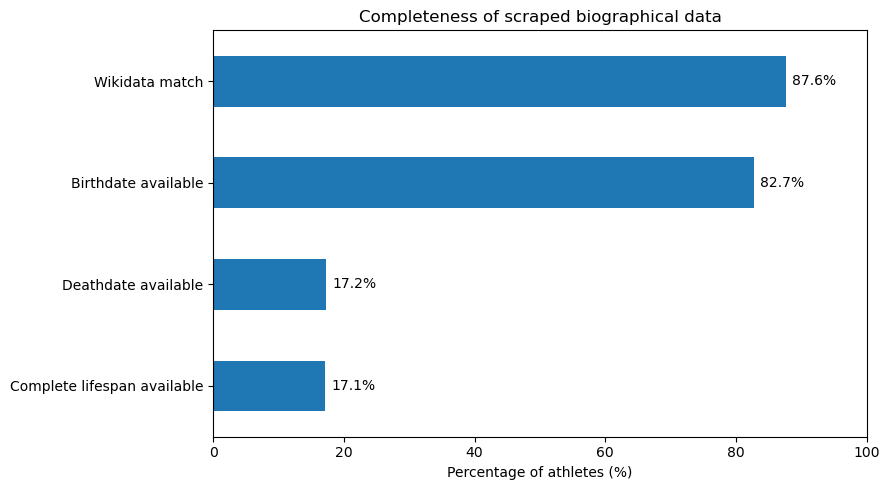

In [42]:
plot_data = lifespan_summary.drop(index="Total athletes")

ax = plot_data["percentage"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

ax.set_title("Completeness of scraped biographical data")
ax.set_xlabel("Percentage of athletes (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)

for bar in ax.patches:
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

In [43]:
lifespan_quality["status"].fillna("Unknown").value_counts()

status
Alive      1570
Unknown     676
Dead        465
Name: count, dtype: int64

In [44]:
def classify_lifespan(row):
    if row["has_lifespan"]:
        return "Complete lifespan"

    if row["status"] == "Alive":
        return "Alive"

    if row["has_birthdate"]:
        return "Birthdate only, status unknown"

    if row["has_deathdate"]:
        return "Deathdate only"

    return "No dates available"


lifespan_quality["lifespan_category"] = lifespan_quality.apply(
    classify_lifespan,
    axis=1
)

lifespan_quality["lifespan_category"].value_counts()

lifespan_category
Alive                             1570
Complete lifespan                  463
No dates available                 449
Birthdate only, status unknown     227
Deathdate only                       2
Name: count, dtype: int64

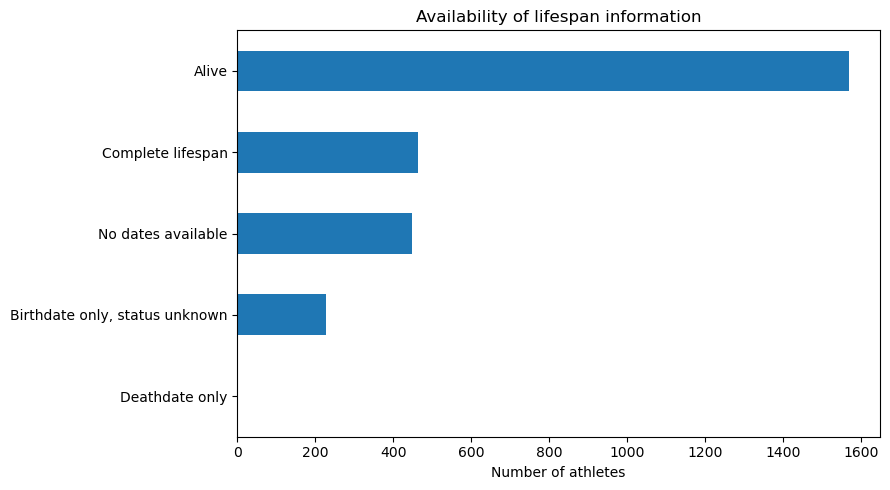

In [45]:
category_counts = (
    lifespan_quality["lifespan_category"]
    .value_counts()
)

ax = category_counts.sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

ax.set_title("Availability of lifespan information")
ax.set_xlabel("Number of athletes")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [46]:
# One suspicious flag per athlete
suspicious_athletes = (
    quality_df.groupby("ID")["suspicious"]
    .any()
)

# Add it to lifespan_quality
lifespan_quality["suspicious"] = (
    lifespan_quality["ID"]
    .map(suspicious_athletes)
    .fillna(False)
)

# Summarize each lifespan category
lifespan_quality_summary = (
    lifespan_quality.groupby("lifespan_category")
    .agg(
        athletes=("ID", "count"),
        suspicious=("suspicious", "sum")
    )
)

lifespan_quality_summary["not_flagged"] = (
    lifespan_quality_summary["athletes"]
    - lifespan_quality_summary["suspicious"]
)

lifespan_quality_summary

,athletes,suspicious,not_flagged
lifespan_category,,,
Alive,1570,29,1541
"Birthdate only, status unknown",227,28,199
Complete lifespan,463,48,415
Deathdate only,2,1,1
No dates available,449,0,449


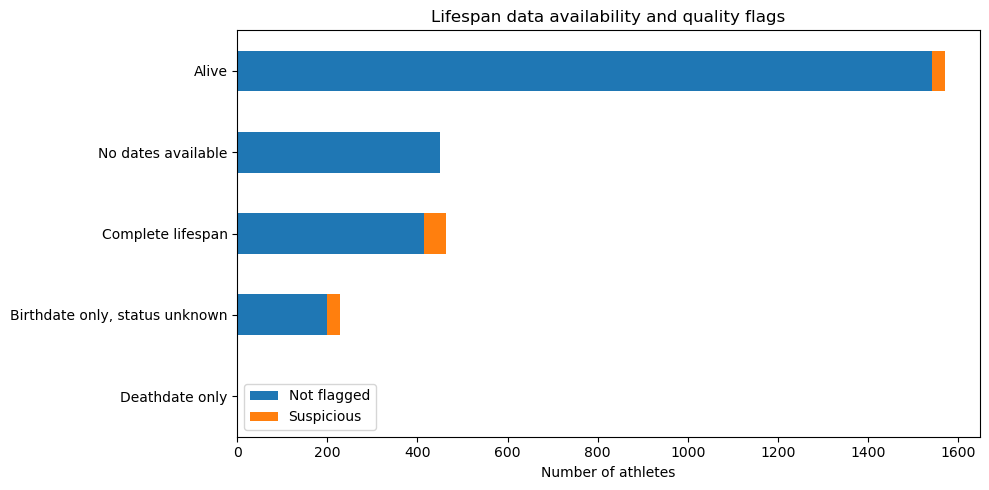

In [47]:
plot_data = lifespan_quality_summary[
    ["not_flagged", "suspicious"]
].sort_values("not_flagged")

ax = plot_data.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 5)
)

ax.set_title("Lifespan data availability and quality flags")
ax.set_xlabel("Number of athletes")
ax.set_ylabel("")
ax.legend(["Not flagged", "Suspicious"])

plt.tight_layout()
plt.show()

# Investigate generations

In [49]:
decade_df = quality_df.copy()

decade_df["decade"] = (
    decade_df["Year"] // 10 * 10
)

decade_df = decade_df.drop_duplicates(
    subset=["ID", "decade"]
)

decade_df = decade_df.merge(
    lifespan_quality[
        ["ID", "lifespan_category", "suspicious"]
    ],
    on="ID",
    how="left",
    suffixes=("", "_athlete")
)

In [50]:
decade_summary = (
    decade_df.groupby(
        ["decade", "lifespan_category"]
    )["ID"]
    .nunique()
    .unstack(fill_value=0)
)

decade_percentage = (
    decade_summary
    .div(decade_summary.sum(axis=1), axis=0)
    * 100
)

decade_percentage.round(1)

lifespan_category,Alive,"Birthdate only, status unknown",Complete lifespan,Deathdate only,No dates available
decade,,,,,
1890,0.0,50.0,50.0,0.0,0.0
1900,0.0,5.1,66.7,0.0,28.2
1910,2.3,13.6,72.7,0.0,11.4
1920,1.9,2.9,76.2,1.0,18.1
1930,4.0,13.3,66.7,0.0,16.0
1940,3.3,7.8,57.8,0.0,31.1
1950,11.4,15.2,54.3,0.0,19.0
1960,34.4,8.7,38.8,0.0,18.1
1970,56.7,8.2,21.9,0.0,13.3


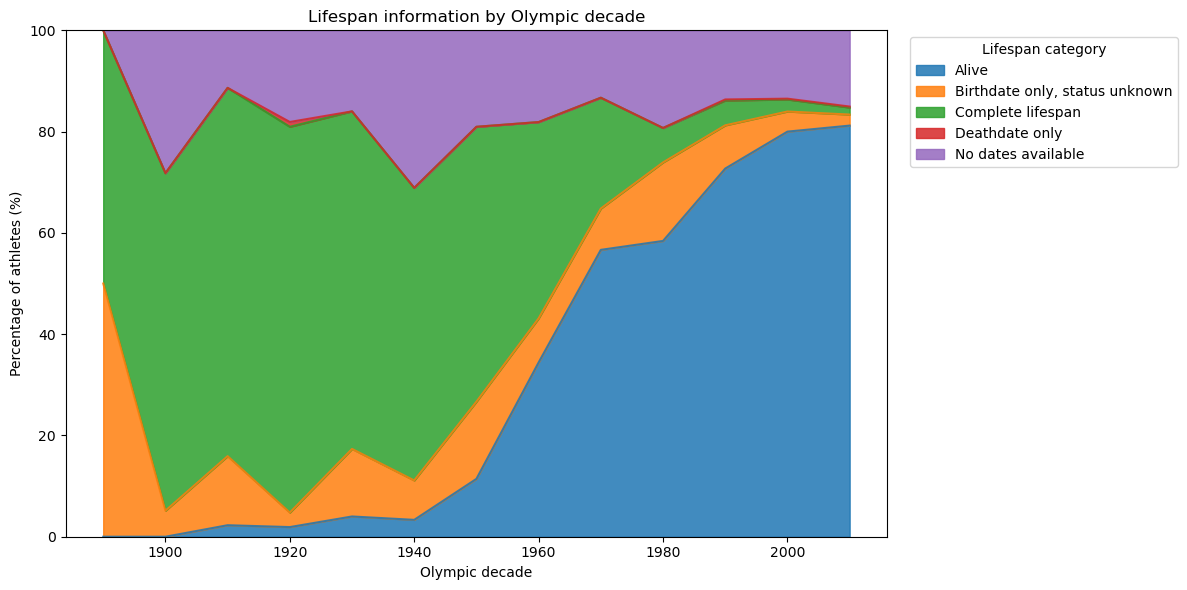

In [51]:
ax = decade_percentage.plot(
    kind="area",
    stacked=True,
    figsize=(12, 6),
    alpha=0.85
)

ax.set_title("Lifespan information by Olympic decade")
ax.set_xlabel("Olympic decade")
ax.set_ylabel("Percentage of athletes (%)")
ax.set_ylim(0, 100)

ax.legend(
    title="Lifespan category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

# investigate suspicious matches by decades

In [52]:
decade_quality = (
    quality_df[["ID", "Year"]]
    .drop_duplicates()
    .copy()
)

decade_quality["decade"] = (
    decade_quality["Year"] // 10 * 10
)

decade_quality = decade_quality.drop_duplicates(
    subset=["ID", "decade"]
)

decade_quality["suspicious"] = (
    decade_quality["ID"]
    .map(
        quality_df.groupby("ID")["suspicious"].any()
    )
)

decade_quality_summary = (
    decade_quality.groupby("decade")
    .agg(
        athletes=("ID", "count"),
        suspicious=("suspicious", "sum"),
        suspicious_percentage=("suspicious", "mean")
    )
)

decade_quality_summary["suspicious_percentage"] *= 100

decade_quality_summary.round(1)

,athletes,suspicious,suspicious_percentage
decade,,,
1890,2,1,50.0
1900,39,5,12.8
1910,44,5,11.4
1920,105,6,5.7
1930,75,5,6.7
1940,90,8,8.9
1950,105,13,12.4
1960,276,18,6.5
1970,233,12,5.2


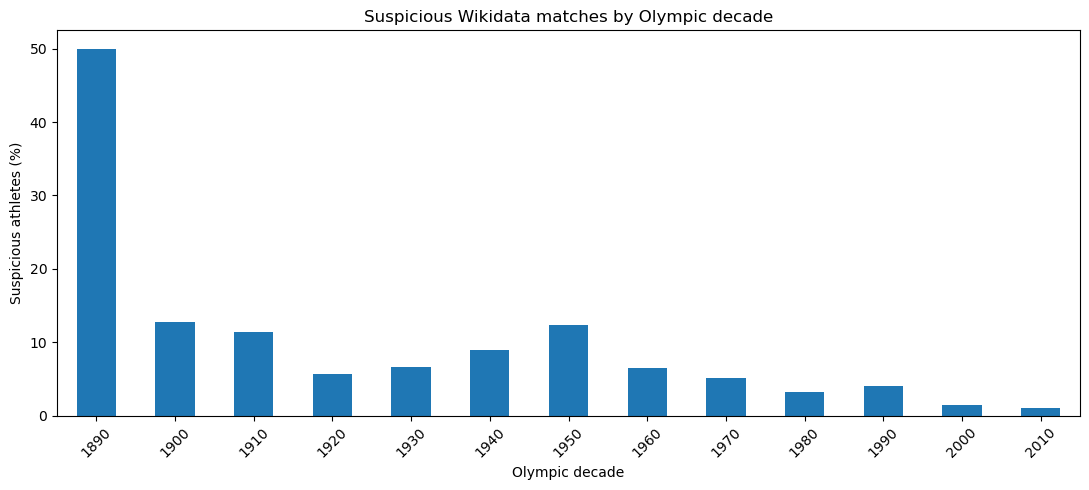

In [53]:
ax = decade_quality_summary["suspicious_percentage"].plot(
    kind="bar",
    figsize=(11, 5),
    rot=45
)

ax.set_title("Suspicious Wikidata matches by Olympic decade")
ax.set_xlabel("Olympic decade")
ax.set_ylabel("Suspicious athletes (%)")

plt.tight_layout()
plt.show()

# add implausible living status as a quality check

In [54]:
# Work with one row per athlete
living_quality = lifespan_quality.copy()

living_quality["birth_year"] = pd.to_numeric(
    living_quality["birthdate"].str.extract(r"^(\d{4})")[0],
    errors="coerce"
)

living_quality["age_in_2026"] = (
    2026 - living_quality["birth_year"]
)

living_quality["implausibly_alive"] = (
    (living_quality["status"] == "Alive")
    & (living_quality["age_in_2026"] > 120)
)

living_quality["implausibly_alive"].sum()

1

In [55]:
pd.crosstab(
    living_quality["implausibly_alive"],
    living_quality["suspicious"]
)

suspicious,False,True
implausibly_alive,,
False,2605,105
True,0,1
